In [1]:
#Imports
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.mpl.ticker as cticker
import cartopy.feature as feature
from cartopy.util import add_cyclic_point

In [2]:
path = '/home/bward23/clim680/assignment1/sstv6.nc'
ds = xr.open_dataset(path) #Grabs dataset from file path
ds_04_16 = ds.sel(time = slice('2004-01-01', '2016-12-01')) #Obtains the 2004 - 2016 time slice
month_mean = ds.groupby('time.month').mean(dim = 'time') #Averages yearly data by months

Text(0.5, 0.85, 'Sea Surface Temperatures (2004 - 2016) Plotted by Month')

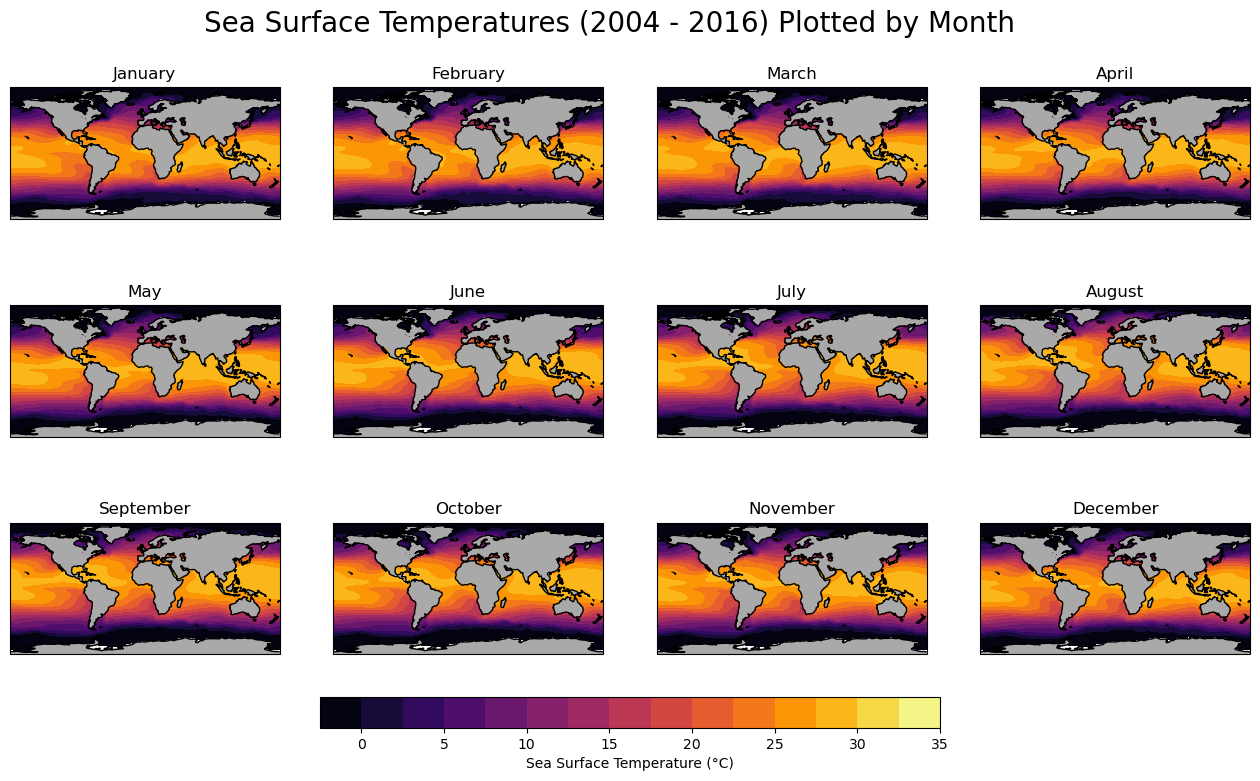

In [33]:
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

fig, ax = plt.subplots(3, 4, figsize=(16, 11), subplot_kw = {'projection': ccrs.PlateCarree()})
levels = np.linspace(-2.5, 35, 16) #Defines max and min value for all plots, actual max and min found in code chunk below this one

for idx, month in enumerate(months):
    axis = ax.flat[idx]

    sst_cyclic, lon_cyclic = add_cyclic_point(month_mean['sst'][idx], coord=ds['lon']) #Resolves longitude wrapping
    
    plot = axis.contourf(lon_cyclic, ds['lat'], sst_cyclic, transform = ccrs.PlateCarree(), cmap = 'inferno', levels = levels)
    axis.coastlines()
    axis.add_feature(feature.LAND, color = 'darkgray')
    axis.add_feature(feature.LAKES, color = 'darkgray') #Grays out land and lakes
    axis.set_title(month)

fig.subplots_adjust(hspace = -0.1)
fig.colorbar(plot, ax = ax, orientation = 'horizontal', label = 'Sea Surface Temperature (°C)', pad = 0.05, shrink = 0.5)
fig.suptitle('Sea Surface Temperatures (2004 - 2016) Plotted by Month', fontsize = 20, y = 0.85)

In [30]:
month_mean['sst'].max(), month_mean['sst'].min()

(<xarray.DataArray 'sst' ()> Size: 4B
 np.float32(32.687984),
 <xarray.DataArray 'sst' ()> Size: 4B
 np.float32(-2.0343943))